# 🚀 Session 7 – Supervised Learning (Regression)
## Linear, Multiple, and Polynomial Regression with scikit-learn

⏱ Estimated Time: 90 minutes

---

## 🎯 Where we are

Sessions 5 and 6 were about **classification** — predicting a **category** (does this person have a bank account? which iris species?). This session switches to **regression** — predicting a **continuous number**.

> A real-estate agent in **Dar es Salaam** pricing a house does not output "yes/no". They output a **price in TZS** — a number. That is regression.

We build up in three steps, then learn to tune and validate properly:

1. **Simple Linear Regression** — one feature, one straight line.
2. **Multiple Linear Regression** — many features at once; interpret the coefficients.
3. **Polynomial Regression** — bend the line to fit **curved** relationships, using `PolynomialFeatures` inside a `Pipeline`.

Then: evaluate with **MSE / RMSE / R²**, diagnose with **residual plots**, tune the **polynomial degree** with `GridSearchCV`, and see firsthand how **high-degree polynomials overfit**.

> 🆕 Unlike the tree and SVM/k-NN models, the mechanics of regression were **not** covered in Orange (AI Wizards), so we build everything from the ground up here.

---

**Session Objective**
- Build **simple**, **multiple**, and **polynomial** regression models with scikit-learn.
- Evaluate with **MSE, RMSE, and R²**; diagnose with **scatter and residual plots**.
- Use **cross-validation** and **`GridSearchCV`** to tune model complexity (polynomial degree) **without data leakage**.
- Compare simple-vs-polynomial models and discuss **which features are significant** from the coefficients.

**Datasets:** We use the **Dar es Salaam housing** dataset throughout the lesson, and the **Dar es Salaam used-car** dataset for the capstone project.

## 🏠 The Scenario: Pricing Dar es Salaam Houses (40 minutes)

You are a data analyst for a property research team. Each row of `dar_housing.csv` is a house that was listed for sale.

| Column | Meaning |
|--------|---------|
| `size_sqm` | House/plot size in square metres |
| `bedrooms` | Number of bedrooms |
| `bathrooms` | Number of bathrooms |
| `age_years` | Age of the building in years |
| `distance_cbd_km` | Distance to the city centre (Posta/CBD) in km |
| `location` | Neighbourhood (Kinondoni, Ilala, Masaki, …) |
| `garage` | Has a parking garage (1) or not (0) |
| `price_million_tzs` | **Target** — sale price in millions of TZS |

### 🛠️ **The Implementation Flow**

#### **1. Import Libraries and Data**

In [1]:
# Install scikit-learn if you haven't already
# !pip install scikit-learn

In [2]:
## Import necessary libraries

# Models
from sklearn.linear_model import LinearRegression

# Preprocessing for polynomial regression and pipelines
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Pipelines and column-wise transforms
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Splitting, cross-validation, tuning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold

# Evaluation metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Data handling and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
## Load the dataset
data = pd.read_csv('dar_housing.csv')
data.head()

,size_sqm,bedrooms,bathrooms,age_years,distance_cbd_km,location,garage,price_million_tzs
0,134,3,1.0,16,3.3,Masaki,1,197.9
1,73,1,1.0,25,18.2,Temeke,1,90.5
2,154,4,3.0,7,1.2,Kinondoni,1,183.7
3,162,3,2.0,13,11.5,Kinondoni,1,176.7
4,35,1,1.0,15,4.4,Kigamboni,1,32.8


In [4]:
# Shape and data types
print("Shape (rows, columns):", data.shape)
print()
data.info()

Shape (rows, columns): (600, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   size_sqm           600 non-null    int64  
 1   bedrooms           600 non-null    int64  
 2   bathrooms          594 non-null    float64
 3   age_years          600 non-null    int64  
 4   distance_cbd_km    594 non-null    float64
 5   location           600 non-null    object 
 6   garage             600 non-null    int64  
 7   price_million_tzs  600 non-null    float64
dtypes: float64(3), int64(4), object(1)
memory usage: 37.6 KB

- **600 houses, 8 columns.** The target `price_million_tzs` is **continuous** → regression.
- `bathrooms` and `distance_cbd_km` have a few **missing values** — we fill them with the median.
- `location` is **categorical** — we one-hot encode it before using it in a model.

#### **Data Cleaning**

In [5]:
# Fill the few missing numeric values with the median (robust to outliers)
data['bathrooms'] = data['bathrooms'].fillna(data['bathrooms'].median())
data['distance_cbd_km'] = data['distance_cbd_km'].fillna(data['distance_cbd_km'].median())
print("Missing values remaining:", int(data.isna().sum().sum()))

Missing values remaining: 0

#### **Quick look: which feature drives price?**

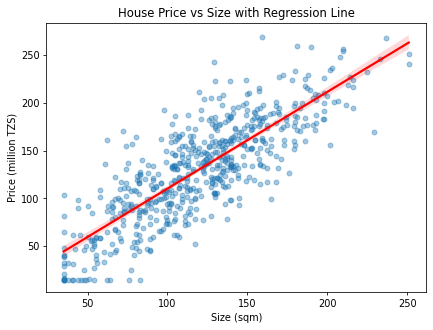

In [6]:
# Scatter with a fitted regression line
sns.regplot(x='size_sqm', y='price_million_tzs', data=data,
            scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.xlabel('Size (sqm)'); plt.ylabel('Price (million TZS)')
plt.title('House Price vs Size')
plt.show()

The relationship looks **linear** — the points follow the straight red line closely. This is a good sign that linear regression will work well for housing (we will contrast this with cars, where the relationship is curved, in the capstone).

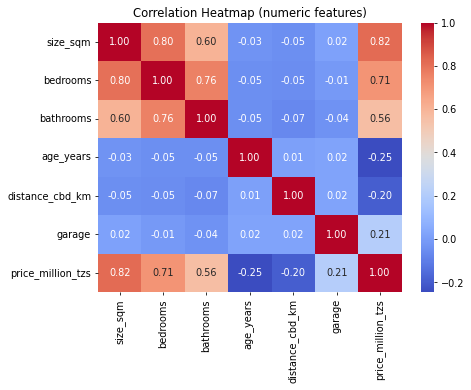

In [7]:
# Correlation heatmap of numeric features
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

`size_sqm` is the strongest **positive** driver; `distance_cbd_km` and `age_years` are **negative** (older / farther = cheaper). All match real intuition.

## 📏 **Simple Linear Regression (one feature)**

We start with one feature, `size_sqm`. The model learns one line:

> **price = intercept + coefficient × size_sqm**

This is **Ordinary Least Squares (OLS)**: it picks the slope and intercept that make the **sum of squared errors** (the gaps between the line and the points) as small as possible.

#### **2. Split the Data**
- We never test on the same data we trained on. `X` holds the feature(s); `y` holds the target.

In [8]:
# Feature (X) and target (y)
X = data[['size_sqm']]
y = data['price_million_tzs']

# 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape[0], " Test:", X_test.shape[0])

Train: 480  Test: 120

#### **3. Train the Model**

In [9]:
# Train simple linear regression
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)
y_pred = simple_model.predict(X_test)
print("Trained!")

Trained!

#### **4. 🔎 Reading the line (interpreting coefficients)**

In [10]:
print(f"Intercept: {simple_model.intercept_:.2f}")
print(f"Coefficient for size_sqm: {simple_model.coef_[0]:.4f}")

Intercept: 7.85
Coefficient for size_sqm: 1.0178

**In plain language:** each extra **square metre** adds about **1.02 million TZS** to the predicted price. The learned line is:

> **price ≈ 7.85 + 1.02 × size_sqm**

In [11]:
# Predict a brand-new 150 sqm house
new_house = pd.DataFrame({'size_sqm': [150]})
print(f"Predicted price for 150 sqm: {simple_model.predict(new_house)[0]:.1f} million TZS")

Predicted price for 150 sqm: 160.5 million TZS

#### **5. Evaluate the Results**

<details>
<summary>What do MSE, RMSE and R² mean?</summary>

* **MSE (Mean Squared Error):** average of squared errors. Squaring punishes big mistakes; units are squared (hard to read).
* **RMSE (Root MSE):** square root of MSE — back in **original units** (million TZS). Reads as "typical error". **Lower is better.**
* **R² (R-squared):** share of price variation the model **explains**, 0–1. **Closer to 1 is better.**
</details>

In [12]:
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f} million TZS")
print(f"R2:   {r2:.3f}")

MSE:  933.42
RMSE: 30.55 million TZS
R2:   0.657

🔎 **Interpretation**: using size alone, predictions are off by ~30.6M on average, explaining **66%** of price variation. Decent for one feature — but a house is more than its size. Time to add features.

**Practice Task:**
1. Re-run the simple model using `distance_cbd_km` as the only feature.
2. Is the coefficient positive or negative? Does the sign make sense?
3. Compare its R² to the size-based model. Which single feature predicts price better?

In [ ]:
# Your code here


## 🧮 **Multiple Linear Regression (many features)**

A real valuation uses everything at once. Multiple regression learns **one coefficient per feature**:

> **price = intercept + c₁·size + c₂·bedrooms + … + cₙ·feature**

#### **Encoding the categorical feature**
`location` is text, so we one-hot encode it (`drop_first=True` leaves one neighbourhood as the baseline).

In [13]:
# One-hot encode 'location'
data_encoded = pd.get_dummies(data, columns=['location'], drop_first=True)

# Features and target
feature_cols = [c for c in data_encoded.columns if c != 'price_million_tzs']
X = data_encoded[feature_cols]
y = data_encoded['price_million_tzs']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Number of features after encoding:", X.shape[1])

Number of features after encoding: 11

In [14]:
# Train multiple linear regression
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_multi = multi_model.predict(X_test)
print("Trained on all features!")

Trained on all features!

#### 🔎 **Interpreting the coefficients — which features matter?**
Each coefficient is how that feature moves the price (in million TZS), holding the others fixed.

In [15]:
coef_table = pd.DataFrame({
    'feature': feature_cols, 'coefficient': multi_model.coef_
}).sort_values('coefficient', ascending=False).reset_index(drop=True)
print(f"Intercept: {multi_model.intercept_:.2f}")
coef_table.round(3)

,feature,coefficient
0,location_Masaki,55.496
1,location_Mikocheni,26.313
2,garage,9.326
3,location_Kinondoni,6.753
4,bedrooms,5.940
5,bathrooms,3.647
6,size_sqm,0.827
7,age_years,-0.966
8,distance_cbd_km,-1.696
9,location_Temeke,-2.047


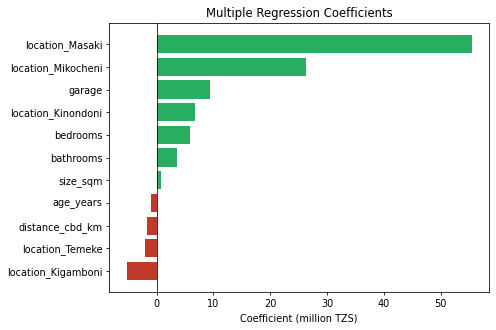

In [16]:
# Visualize coefficients
order = coef_table.sort_values('coefficient')
colors = ['#c0392b' if c < 0 else '#27ae60' for c in order['coefficient']]
plt.barh(order['feature'], order['coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient (million TZS)')
plt.title('Multiple Regression Coefficients')
plt.show()

**What the model learned about Dar es Salaam:**
- 🟢 Being in **Masaki** adds ~**55M TZS** vs the baseline neighbourhood — the strongest effect by far. **Mikocheni** adds ~26M. **Location dominates.**
- 🟢 A **garage** ~9M; each **bedroom** ~6M; each **bathroom** ~3.6M.
- 🟢 Each **square metre** now adds only ~0.83M (down from 1.02M in the simple model) — because size no longer has to "stand in" for bedrooms and location.
- 🔴 Each **year of age** ~−1M; each **km from CBD** ~−1.7M.

Every sign is intuitive — a strong sign the model is sound.

#### **Evaluate and compare to the simple model**

In [17]:
rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi))
r2_multi   = r2_score(y_test, y_pred_multi)
print(f"Simple model    -> RMSE: 30.55  R2: 0.657")
print(f"Multiple model  -> RMSE: {rmse_multi:.2f}  R2: {r2_multi:.3f}")

Simple model    -> RMSE: 30.55  R2: 0.657
Multiple model  -> RMSE: 18.99  R2: 0.867

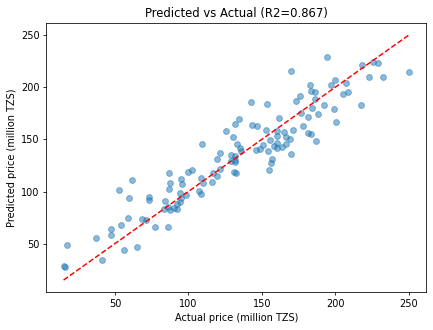

In [18]:
# Predicted vs actual for the multiple model
plt.scatter(y_test, y_pred_multi, alpha=0.5)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual price (million TZS)')
plt.ylabel('Predicted price (million TZS)')
plt.title(f'Predicted vs Actual (R2 = {r2_multi:.3f})')
plt.show()

🔎 **R² jumped 0.66 → 0.87** and **RMSE dropped ~30.6M → ~19.0M**. More relevant features ⇒ a better model, because price genuinely depends on more than size. The points now hug the diagonal closely.

## 🔬 **Checking Assumptions: Residual Analysis**

A linear model is trustworthy only if its **residuals** (`actual − predicted`) behave well. Briefly, OLS assumes **linearity**, **constant error spread (homoscedasticity)**, and **independent errors**. Two quick visual checks:

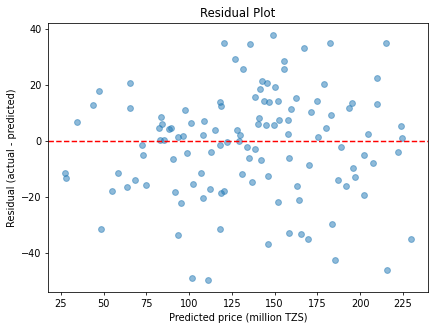

In [19]:
# 1. Residual plot: should be a shapeless cloud around 0
residuals = y_test - y_pred_multi
plt.scatter(y_pred_multi, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted price (million TZS)')
plt.ylabel('Residual (actual - predicted)')
plt.title('Residual Plot')
plt.show()

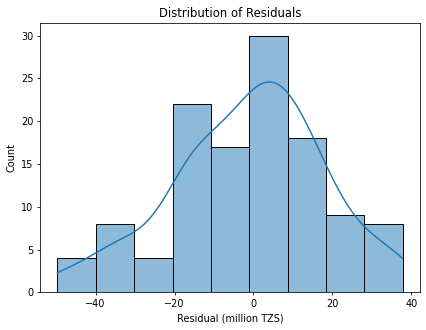

In [20]:
# 2. Distribution of residuals: should be roughly bell-shaped, centred on 0
sns.histplot(residuals, kde=True)
plt.xlabel('Residual (million TZS)')
plt.title('Distribution of Residuals')
plt.show()

🔎 **Interpretation**
- The residual plot is a **shapeless cloud around 0** — no funnel (so the error spread is roughly constant → homoscedasticity holds) and no curve (so linearity holds). ✅
- The histogram is **roughly bell-shaped and centred near 0**. ✅
- If you *did* see a clear curve, that would signal the relationship is **non-linear** — exactly the cue to try **polynomial features**, which we explore next.

## 📐 **Polynomial Regression & Pipelines**

What if the relationship were **curved**? Polynomial regression handles this with a simple trick: **we don't change the model — we add features.** Adding `size²` lets a *linear* model fit a curve:

> **price = c₁·size + c₂·size² + intercept**

`PolynomialFeatures(degree=2)` creates these extra columns automatically. Let's see it on a tiny example.

In [21]:
# What PolynomialFeatures does to 2 features at degree 2
demo = np.array([[2, 3]])
pf = PolynomialFeatures(degree=2, include_bias=False)
expanded = pf.fit_transform(demo)
print("Original:      ", demo.tolist())
print("Feature names: ", pf.get_feature_names_out(['a', 'b']).tolist())
print("Expanded:      ", expanded.tolist())

Original:       [[2, 3]]
Feature names:  ['a', 'b', 'a^2', 'a b', 'b^2']
Expanded:       [[2.0, 3.0, 4.0, 6.0, 9.0]]

So `degree=2` turned 2 features into 5: the originals plus `a²`, `a·b` (interaction) and `b²`.

### 🔗 Why a `Pipeline`?

Polynomial regression needs several ordered steps: **impute → polynomial expand → scale → fit**. A `Pipeline` chains them into one object so they always run in the right order — and, crucially, it **prevents data leakage**.

<details>
<summary>⚠️ What is data leakage, and how do pipelines prevent it?</summary>

**Data leakage** is when information from the **test set** sneaks into training. The model then looks great in the notebook but **fails in production**.

Example: `StandardScaler` subtracts the mean / divides by the std. If you compute that on the **whole dataset before splitting**, the scaler has already "seen" the test rows. Same with the imputer's median.

**The fix:** split first, then fit every transform on the **training data only**. Inside cross-validation this must happen **per fold**. A `Pipeline` does this automatically — its single most important benefit.
</details>

Our data has **numeric** columns (impute → poly → scale) and a **categorical** column (one-hot). A `ColumnTransformer` applies different steps to different columns.

In [22]:
# Declare column groups
num_features = ['size_sqm', 'bedrooms', 'bathrooms', 'age_years', 'distance_cbd_km', 'garage']
cat_features = ['location']
target = 'price_million_tzs'

X = data.drop(columns=[target])
y = data[target]

# Split FIRST (lock away the test set -> no leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
# Numeric branch: impute -> polynomial -> scale ;  Categorical branch: one-hot
categorical_pipeline = Pipeline([('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))])

def make_poly_pipeline(degree):
    numeric_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scale', StandardScaler())
    ])
    pre = ColumnTransformer([
        ('num', numeric_pipeline, num_features),
        ('cat', categorical_pipeline, cat_features)
    ])
    return Pipeline([('pre', pre), ('model', LinearRegression())])

# Build a linear (degree 1) and a polynomial (degree 2) version
linear_pipeline = make_poly_pipeline(1).fit(X_train, y_train)
poly_pipeline   = make_poly_pipeline(2).fit(X_train, y_train)

pred_lin = linear_pipeline.predict(X_test)
pred_p2  = poly_pipeline.predict(X_test)
print(f"Linear (deg 1)  -> RMSE: {np.sqrt(mean_squared_error(y_test, pred_lin)):.2f}  R2: {r2_score(y_test, pred_lin):.3f}")
print(f"Poly  (deg 2)   -> RMSE: {np.sqrt(mean_squared_error(y_test, pred_p2)):.2f}  R2: {r2_score(y_test, pred_p2):.3f}")

Linear (deg 1)  -> RMSE: 18.99  R2: 0.867
Poly  (deg 2)   -> RMSE: 19.16  R2: 0.865

🔎 **A crucial result:** for **housing**, degree 2 does **not** help — it is actually a hair *worse* (R² 0.865 vs 0.867). Why? Because the housing relationships really are **linear** (we saw it in the scatter plot). Adding curves just adds noise the model can latch onto.

> This is the heart of the session: **polynomial is not automatically better.** The right complexity must be **chosen by cross-validation**, not assumed. (In the capstone you'll meet the *car* dataset, where curves genuinely help.)

## 🔍 **Tuning the polynomial degree with `GridSearchCV`**

Rather than guess the degree, we let cross-validation choose. The double-underscore path reaches the `degree` parameter inside the pipeline: `pre__num__poly__degree` (read: `pre` → `num` → `poly` → `degree`).

In [24]:
# Search degrees 1, 2, 3 with 5-fold CV (no leakage: transforms refit per fold)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    make_poly_pipeline(2),
    param_grid={'pre__num__poly__degree': [1, 2, 3]},
    cv=kf, scoring='r2', n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best degree:", grid.best_params_)
print(f"Best cross-validated R2: {grid.best_score_:.3f}")

Best degree: {'pre__num__poly__degree': 1}
Best cross-validated R2: 0.880

In [25]:
# Score for each degree tried
results = pd.DataFrame(grid.cv_results_)[
    ['param_pre__num__poly__degree', 'mean_test_score', 'std_test_score']]
results.columns = ['degree', 'mean_cv_r2', 'std_cv_r2']
results.round(3)

,degree,mean_cv_r2,std_cv_r2
0,1,0.880,0.023
1,2,0.874,0.024
2,3,0.847,0.041


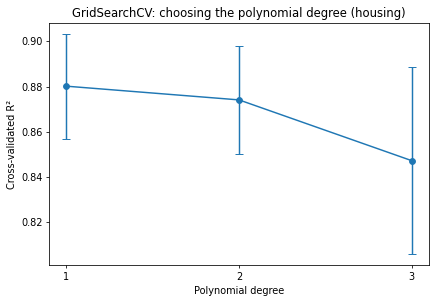

In [26]:
# Plot CV R2 vs degree
plt.errorbar(results['degree'], results['mean_cv_r2'],
             yerr=results['std_cv_r2'], marker='o', capsize=4)
plt.xticks([1, 2, 3])
plt.xlabel('Polynomial degree'); plt.ylabel('Cross-validated R²')
plt.title('GridSearchCV: choosing the polynomial degree (housing)')
plt.show()

🔎 **Interpretation**: CV R² is **highest at degree 1** and *drops* as the degree rises (and the spread grows). Cross-validation correctly tells us the housing data wants a **plain linear model**. Trusting a single training fit (where higher degrees always look better) would have misled us.

## ⚖️ **Overfitting vs Underfitting: the danger of high degrees**

Why not just crank the degree up? Because high-degree polynomials **memorise** the training data and fail to generalize. The clearest demonstration: track **training R²** and **cross-validated R²** as the degree climbs.

In [27]:
# Compare training R2 vs cross-validated R2 across degrees
degrees = [1, 2, 3, 4, 5]
train_scores, cv_scores = [], []
for d in degrees:
    pipe = make_poly_pipeline(d)
    train_scores.append(pipe.fit(X_train, y_train).score(X_train, y_train))
    cv_scores.append(cross_val_score(pipe, X, y, cv=kf, scoring='r2').mean())

for d, tr, cv in zip(degrees, train_scores, cv_scores):
    print(f"degree {d}:  train R2 = {tr:.3f}   CV R2 = {cv:.3f}")

degree 1:  train R2 = 0.891   CV R2 = 0.880
degree 2:  train R2 = 0.897   CV R2 = 0.877
degree 3:  train R2 = 0.909   CV R2 = 0.847
degree 4:  train R2 = 0.931   CV R2 = 0.634
degree 5:  train R2 = 0.965   CV R2 = -629.639

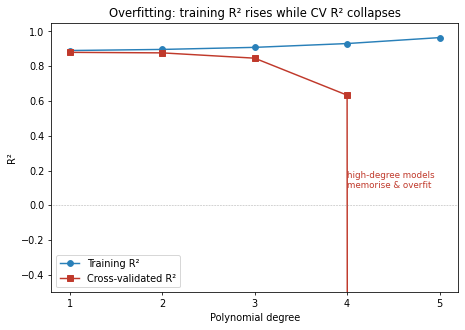

In [28]:
# Visualize the overfitting gap
plt.plot(degrees, train_scores, marker='o', label='Training R²', color='#2980b9')
plt.plot(degrees, cv_scores, marker='s', label='Cross-validated R²', color='#c0392b')
plt.xticks(degrees); plt.ylim(-0.5, 1.05)
plt.axhline(0, color='gray', lw=0.6, ls=':')
plt.xlabel('Polynomial degree'); plt.ylabel('R²')
plt.title('Overfitting: training R² rises while CV R² collapses')
plt.legend()
plt.show()

🔎 **Interpretation — this is the key lesson of the session**
- **Training R² keeps rising** with degree (0.891 → 0.965) — the model fits the training points ever more tightly.
- But **cross-validated R² collapses** (0.880 → **−629**!). At degree 5 the model is so wiggly it predicts wildly on unseen data.
- The growing **gap** between the blue and red lines *is* overfitting. The model has memorised noise instead of learning the pattern.

| Symptom | Diagnosis |
|---------|-----------|
| Train R² high, CV R² much lower | **Overfitting** (degree too high) |
| Train R² low AND CV R² low | **Underfitting** (too simple) |
| Train R² and CV R² both good & close | ✅ Good generalization (here: degree 1) |

**Takeaway:** always judge with **cross-validation on unseen folds**, never training fit alone. For housing, degree 1 wins.

**Practice Task:**
1. Add `Ridge` regression (`from sklearn.linear_model import Ridge`) as the model. Tune **both** `pre__num__poly__degree` and `model__alpha` in one `GridSearchCV`.
2. Does L2 regularization (Ridge) let a higher degree survive without overfitting? Why might that be?
3. Report the best parameters and the test R².

In [ ]:
# Your code here


## 📊 **Putting it all together (housing)**

In [29]:
comparison = pd.DataFrame({
    'Model': ['Simple Linear (size only)', 'Multiple Linear (all features)',
              'Polynomial (degree 2)', 'Best from GridSearch (degree 1)'],
    'Test_RMSE': [30.552, 18.987, 19.159, 18.987],
    'Test_R2':   [0.657, 0.867, 0.865, 0.867]
})
comparison.round(3)

,Model,Test_RMSE,Test_R2
0,Simple Linear (size only),30.552,0.657
1,Multiple Linear (all features),18.987,0.867
2,Polynomial (degree 2),19.159,0.865
3,Best from GridSearch (degree 1),18.987,0.867


**The story:** adding **features** (simple → multiple) gave the big win, R² 0.66 → 0.87. Adding **polynomial complexity** did **not** help here — and cross-validation correctly selected the simple linear model.

##### 🧠 Key takeaways
- **Simple → Multiple** regression: more relevant features usually help; coefficients reveal which features matter (location dominates housing).
- **Polynomial features** let a linear model fit **curves** — but only help when the relationship is genuinely non-linear.
- A **`Pipeline`** chains impute → poly → scale → model and **prevents data leakage** by refitting transforms per CV fold.
- **`GridSearchCV`** chooses the degree by cross-validation; **never** trust training fit alone.
- **High-degree polynomials overfit** — watch the Train-vs-CV gap.

## 🛠️ Mini Project: Build and Compare Regression Models (20 minutes)

**Scenario:** You are the data analyst for a Dar es Salaam property team. Build the best price estimator you can with linear models, using `dar_housing.csv`.

**Data Preparation:**
* Load and clean (median fill), one-hot encode `location`, separate `X`/`y`.
* Train-test split (80/20) with a fixed `random_state` — **split before any transform**.

**Train Models:**
* Simple Linear Regression on your single best feature.
* Multiple Linear Regression on all features.
* A Polynomial pipeline (degree 2) on the numeric features.

**Evaluate:**
* Compute MSE, RMSE and R² on the test set for each.
* Summarise in a comparison table. By how much does adding features help? Does polynomial help here?

**Interpretation:**
* Print the multiple-regression coefficient table. Which three features push price up most? Which down?
* Explain one coefficient in one plain-language sentence.

**Tune & Diagnose:**
* `GridSearchCV` over `pre__num__poly__degree` in `[1, 2, 3]` with 5-fold CV. Report the best degree.
* Plot residuals of your best model. Do they scatter randomly around 0?
* Compare Train R² vs CV R² across degrees. Where does overfitting begin?

Write Markdown notes at each step.

## 🚀 Capstone Project: Predicting Used-Car Prices (25 minutes)

Now apply everything to a **new dataset where the relationship is curved** — so polynomial regression should genuinely shine, unlike housing.

**Dataset:** `car_prices.csv` — used cars on an East African marketplace.

| Column | Meaning |
|--------|---------|
| `age_years` | Age of the car in years |
| `mileage_k_km` | Distance driven (thousands of km) |
| `engine_size` | Engine displacement (litres) |
| `horsepower` | Engine power (hp) |
| `fuel` | petrol / diesel / hybrid |
| `transmission` | manual / automatic |
| `brand` | Toyota, Suzuki, Nissan, Mercedes, BMW |
| `price_million_tzs` | **Target** — price in millions of TZS |

> 💡 **Hint:** cars **depreciate** fast when new, then level off — a strongly **curved** price-vs-age relationship. Plot `price_million_tzs` against `age_years` first and you should see it. Here, polynomial regression is expected to beat plain linear.

**Tasks:**
1. **Load & Clean:** Load the data, report missing values per column.
2. **Exploratory Analysis:** Plot price vs `age_years` (and one other numeric feature). Argue from the plot whether a linear or non-linear model is appropriate.
3. **Train/Test Split:** 80/20 with a fixed seed, **before** any preprocessing. Explain why this ordering matters (leakage).
4. **Baseline Linear Pipeline:** Impute → scale → one-hot → `LinearRegression`. Report test RMSE and R².
5. **Polynomial Pipeline:** Add `PolynomialFeatures` to the numeric branch. Report test RMSE and R². Does the curve help **here**? (It should — contrast with housing.)
6. **Tune the Degree:** `GridSearchCV` over the polynomial degree (optionally a `Ridge` `alpha`) with cross-validation. Report the best degree and CV score.
7. **Final Evaluation:** Evaluate the tuned pipeline on the test set (RMSE, MAE, R²); plot predicted vs actual.
8. **Overfitting Check:** Compare Train R² vs CV R² across degrees; state where overfitting begins.
9. **Coefficients/Significance:** Comment on which features most influence car price.
10. **Conclusions:** Summarise which model and features gave the best predictions, and **contrast with the housing lesson** — why did polynomial help for cars but not houses?

**Deliverable:** A Jupyter notebook with all code, outputs, plots (predicted-vs-actual, residuals, degree-vs-CV), answers to every task, and a short written conclusion.

By completing this capstone, learners demonstrate mastery of simple, multiple and polynomial regression, evaluation metrics (MSE/RMSE/R²), pipelines, `GridSearchCV` tuning, residual diagnostics, and a practical understanding of when added model complexity is — and isn't — worth it.